# Exploring Portfolio Size: How Many Stocks Are Enough?

**Instructor analysis notebook | Equal-weight portfolios | Exploratory study (not the final student challenge)**

You are advising a client who wants strong diversification without holding unnecessarily many stocks. Before setting the competition rules, we will **search for low-volatility equal-weight portfolios for each size from 5 to 50 stocks**. We will compare three intuitive selection rules and refine their results with stock swaps.

**Goal:** produce evidence to help select an appropriate maximum number of stocks, a fixed risk benchmark and a fair competition threshold. A heuristic search does **not** prove the global minimum for any portfolio size.

## 1. Data and a common comparison sample

Use the same `SP500_comp_data.xlsx` price file as in the previous diversification lesson. Every candidate portfolio is evaluated using **the same set of dates**. We use daily **log returns**, equal weights and annualized standard deviation (`sqrt(252)`).

Missing-data policy: discard dates with a missing price in any retained stock; we do not silently compare portfolios on different samples. If the number of discarded dates is large, reconsider the universe/data quality before interpreting the results.

In [9]:
import pandas as pd
import numpy as np
import tqdm
import matplotlib.pyplot as plt

In [ ]:



# Download prices directly from GitHub
url = "https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/Finance_Technology/Tema_2_Carteras_Intro/data/SP500_comp_data.xlsx"

prices = pd.read_excel(url, index_col="Date")

# Prepare the price data
prices.index = pd.to_datetime(prices.index)
prices = prices.sort_index().apply(pd.to_numeric, errors="coerce")
prices = prices.where(prices > 0)

# Remove stocks with more than 20% missing prices
n_stocks_initial = prices.shape[1]
prices = prices.loc[:, prices.isna().mean() <= 0.20]

# Remove all remaining rows with missing prices
prices = prices.dropna()

# Calculate daily log returns
returns = np.log(prices / prices.shift(1)).dropna()

# Competition parameters
MIN_K, MAX_K = 5, 30
REFERENCE_VOL = 0.07963123
VOL_LIMIT = 0.08042754

# Dataset information
print(f"Initial stocks: {n_stocks_initial}")
print(f"Eligible stocks: {returns.shape[1]}")
print(f"Return dates: {len(returns)}")
print(f"Sample: {returns.index.min().date()} to {returns.index.max().date()}")
print(f"Allowed K: {MIN_K} to {MAX_K}")
print(f"Volatility limit: {VOL_LIMIT:.6%}")

assert returns.shape[1] >= MAX_K and len(returns) >= 3


Initial stocks: 504
Eligible stocks: 325
Return dates: 6832
Sample: 1996-07-01 to 2023-08-22
Allowed K: 5 to 30
Volatility limit: 8.042754%


## 2. Portfolio risk and selection strategies

Let `cov` denote the daily covariance matrix. For an equally weighted subset of `K` stocks, the portfolio variance is the **mean of the entries of its covariance submatrix**; multiply by 252 to annualize the variance.

We use three strategies:

1. **Low volatility** — take the `K` stocks with the lowest individual volatility.
2. **Low correlation** — start from a low-volatility stock and repeatedly add the stock with the smallest average correlation to the selected ones.
3. **Minimum portfolio volatility (greedy)** — add the stock that yields the lowest portfolio volatility after inclusion.

The correlation rule is only a heuristic: it ignores the new stock’s standalone volatility.

In [2]:
tickers = list(returns.columns)
n = len(tickers)
cov = returns.cov().to_numpy()
corr = returns.corr().to_numpy()
variances = np.diag(cov)

# Lower variance and ticker index break ties deterministically.
low_vol_order = np.lexsort((np.arange(n), variances))
start_stocks = low_vol_order[:min(5, n)]  # Different initial assets.


def volatility(selected):
    """Annualized volatility of an equal-weight portfolio."""
    selected = np.asarray(selected, dtype=int)
    return float(np.sqrt(max(0, 252 * cov[np.ix_(selected, selected)].mean())))


def forward_path(start, method, max_k):
    """Construct nested portfolios, one stock at a time."""
    selected = [int(start)]
    path = {}
    while len(selected) < max_k:
        remaining = np.array([j for j in range(n) if j not in selected])
        if method == "Low correlation":
            quality = np.nanmean(corr[np.ix_(remaining, selected)], axis=1)
        else:
            # Equal weights: minimizing variance = minimizing sum of covariances.
            current_total = cov[np.ix_(selected, selected)].sum()
            quality = current_total + 2 * cov[np.ix_(remaining, selected)].sum(axis=1) + variances[remaining]
        selected.append(int(remaining[np.argmin(quality)]))
        if len(selected) >= MIN_K:
            path[len(selected)] = selected.copy()
    return path


## 3. Improve candidate portfolios by swaps

A greedy search may make poor early choices. Once a portfolio has `K` stocks, we test **one-for-one exchanges** between a selected stock and any unselected stock. We keep improving swaps until none reduces volatility. Portfolio size and equal weights stay fixed.

For speed, we compute candidate swap variances using the covariance matrix rather than recalculating daily returns for every trial. This is mathematically equivalent on the common sample.

In [3]:
def improve_swaps(selected, max_rounds=15):
    """Reduce variance by swapping one chosen stock with one unused stock."""
    selected = list(selected)
    K = len(selected)
    for _ in range(max_rounds):
        remaining = np.array([j for j in range(n) if j not in selected])
        if len(remaining) == 0:
            break

        current = cov[np.ix_(selected, selected)].sum()
        sums_selected = cov[np.ix_(selected, selected)].sum(axis=1)
        sums_remaining = cov[np.ix_(remaining, selected)].sum(axis=1)

        # For each replacement: remove the old stock's terms and add new terms.
        # Rows = unused stocks; columns = positions to replace.
        trials = (current
                  - 2 * sums_selected[None, :] + variances[np.asarray(selected)][None, :]
                  + 2 * (sums_remaining[:, None] - cov[np.ix_(remaining, selected)])
                  + variances[remaining, None])
        r, p = np.unravel_index(np.argmin(trials), trials.shape)
        if trials[r, p] >= current - 1e-12:
            break
        selected[p] = int(remaining[r])
    return sorted(selected)


## 4. Run the exploratory search for every K = 5, ..., 50

For each size, evaluate the low-volatility baseline, the two forward strategies from several initial stocks, and then apply swaps to promising candidates. Export one winning subset **for each size**, together with the results of each strategy.

The progress bar shows the sizes completed; actual runtime depends on the number of stocks and how many swaps are beneficial.

In [7]:
# Construct complete forward paths once; reuse their portfolios for every K.
paths = {
    (method, int(start)): forward_path(start, method, MAX_K)
    for method in ["Low correlation", "Minimum portfolio volatility"]
    for start in start_stocks
}

records = []
for K in tqdm.tqdm(range(MIN_K, MAX_K + 1), desc="Portfolio sizes"):
    candidates = {"Low volatility": list(low_vol_order[:K])}

    for method in ["Low correlation", "Minimum portfolio volatility"]:
        # Best starting point for this K, before swaps.
        candidates[method] = min(
            (paths[(method, int(s))][K] for s in start_stocks),
            key=volatility
        )

    # Improve every strategy; consider all starting points for greedy search.
    improved = []
    for method, subset in candidates.items():
        improved.append((method + " + swaps", improve_swaps(subset)))
    for method in ["Low correlation", "Minimum portfolio volatility"]:
        for start in start_stocks:
            improved.append((method + " + swaps (multistart)",
                             improve_swaps(paths[(method, int(start))][K])))

    best_method, best_stocks = min(improved, key=lambda item: volatility(item[1]))
    row = {
        "K": K,
        "Low volatility (%)": 100 * volatility(candidates["Low volatility"]),
        "Low correlation (%)": 100 * volatility(candidates["Low correlation"]),
        "Greedy min-vol (%)": 100 * volatility(candidates["Minimum portfolio volatility"]),
        "Best after swaps (%)": 100 * volatility(best_stocks),
        "Winning method": best_method,
        "Tickers": ",".join(sorted(tickers[j] for j in best_stocks)),
    }
    records.append(row)

results = pd.DataFrame(records)
display(results.head(10).round(4))


Portfolio sizes: 100%|██████████| 26/26 [00:00<00:00, 54.44it/s]


,K,Low volatility (%),Low correlation (%),Greedy min-vol (%),Best after swaps (%),Winning method,Tickers
0,5,15.2949,22.8695,14.4539,14.4539,Low volatility + swaps,"ED,GIS,HRL,JNJ,MCD"
1,6,15.6263,21.5395,14.3104,14.3104,Low volatility + swaps,"BRO,ED,GIS,HRL,JNJ,MCD"
2,7,15.8616,20.6979,14.1599,14.1599,Low volatility + swaps,"BRO,ED,GIS,HRL,JNJ,MCD,WEC"
3,8,15.5155,20.3948,14.0428,14.0292,Low volatility + swaps,"CHD,ED,GIS,HRL,JNJ,MCD,SO,WST"
4,9,15.1880,20.4267,13.9433,13.9227,Low volatility + swaps,"ED,GIS,HRL,JNJ,MCD,SJM,SO,WMT,WST"
5,10,15.3751,19.9313,13.8113,13.7861,Low volatility + swaps,"ED,GIS,HRL,JNJ,MCD,NEM,SJM,SO,WMT,WST"
6,11,15.5563,19.0717,13.7104,13.6627,Low volatility + swaps,"ACGL,ED,GIS,HRL,JNJ,MCD,NEM,SJM,SO,WMT,WST"
7,12,15.3611,19.0950,13.6263,13.5502,Low volatility + swaps,"ACGL,CLX,ED,GIS,HRL,JNJ,MCD,NEM,SJM,SO,WMT,WST"
8,13,15.2202,18.4616,13.5607,13.4887,Low volatility + swaps,"ACGL,CAG,CLX,ED,GIS,HRL,JNJ,MCD,NEM,SJM,SO,WMT..."
9,14,15.0359,18.2204,13.4943,13.4309,Low volatility + swaps,"ACGL,AJG,CAG,CLX,ED,GIS,HRL,JNJ,MCD,NEM,SJM,SO..."


## 5. Plot the risk-size trade-off

The lowest risk found for a given `K` may **increase** when `K` increases: every portfolio must be equal-weighted and contain exactly `K` stocks. The *best risk for up to K stocks* cannot increase, because it includes all previous sizes. We show both concepts to avoid confusing them.

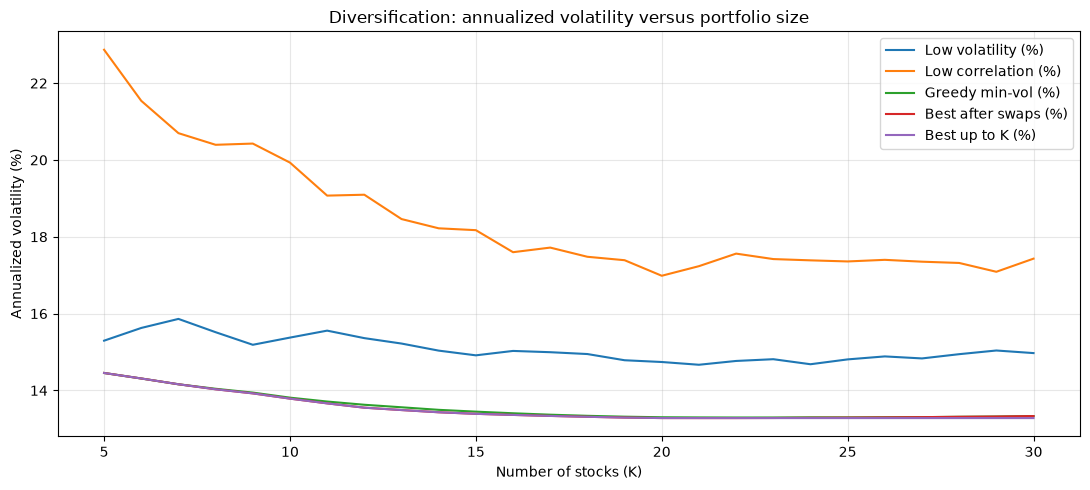

In [10]:
results["Best up to K (%)"] = results["Best after swaps (%)"].cummin()

fig, ax = plt.subplots(figsize=(11, 5))
for col in ["Low volatility (%)", "Low correlation (%)", "Greedy min-vol (%)",
            "Best after swaps (%)", "Best up to K (%)"]:
    ax.plot(results["K"], results[col], label=col)
ax.set(title="Diversification: annualized volatility versus portfolio size",
       xlabel="Number of stocks (K)", ylabel="Annualized volatility (%)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## 6. What maximum size and tolerance might make a good challenge?

Compute the lowest risk **found anywhere in the exploratory range** and the smallest `K` that gets within **1% relative** of it. We do **not** assume that this is the mathematical global minimum. If the qualifying `K` is already 5, the intended competition would not meaningfully distinguish students by portfolio size; consider changing the benchmark or grading rule.

The 1% threshold is **relative**: a benchmark of 9% annual volatility permits at most 9.09%, not 10%.

Best annualized volatility found: 13.2796% (K=22)
1% relative tolerance: 13.4124%
Smallest qualifying K found: 15
Qualifying tickers: ACGL,AJG,CAG,CLX,ED,GIS,HRL,JNJ,LMT,MCD,NEM,SJM,SO,WMT,WST


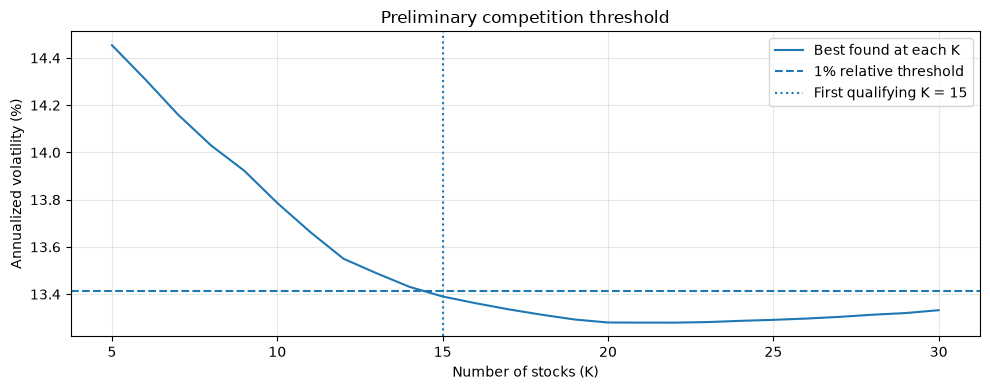

In [11]:
best_row = results.loc[results["Best after swaps (%)"].idxmin()]
benchmark = best_row["Best after swaps (%)"]
threshold = 1.01 * benchmark
qualified = results[results["Best after swaps (%)"] <= threshold + 1e-12]
smallest_k = int(qualified.iloc[0]["K"])

print(f"Best annualized volatility found: {benchmark:.4f}% (K={int(best_row['K'])})")
print(f"1% relative tolerance: {threshold:.4f}%")
print(f"Smallest qualifying K found: {smallest_k}")
print("Qualifying tickers:", qualified.iloc[0]["Tickers"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(results["K"], results["Best after swaps (%)"], label="Best found at each K")
ax.axhline(threshold, linestyle="--", label="1% relative threshold")
ax.axvline(smallest_k, linestyle=":", label=f"First qualifying K = {smallest_k}")
ax.set(xlabel="Number of stocks (K)", ylabel="Annualized volatility (%)",
       title="Preliminary competition threshold")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## 7. Verify and export results for review

Recalculate the best portfolio's volatility directly from its daily returns. Save two files beside the notebook:

- **`portfolio_size_search_results.csv`** — the full comparison for all K, including the tickers of the best portfolio found at each size.
- **`portfolio_size_search_summary.txt`** — sample details, benchmark, proposed threshold and first qualifying K.

**Send me the CSV and TXT after running all cells.** This will let us decide whether the challenge should permit 5–15, 5–20, 5–30 or a different range. The selected cutoff must be fixed before students compete.

In [ ]:
chosen = best_row["Tickers"].split(",")
check_vol = 100 * returns[chosen].mean(axis=1).std() * np.sqrt(252)
assert np.isclose(check_vol, benchmark), "Covariance and direct calculations disagree."

csv_path = Path("portfolio_size_search_results.csv")
txt_path = Path("portfolio_size_search_summary.txt")
results.to_csv(csv_path, index=False, float_format="%.8f")
summary = (f"Prices: {DATA_PATH}\n"
           f"Stocks: {n}\n"
           f"Return dates: {len(returns)}\n"
           f"Sample: {returns.index.min().date()} to {returns.index.max().date()}\n"
           f"Portfolio sizes: {MIN_K} to {MAX_K}\n"
           f"Best found: {benchmark:.6f}% at K={int(best_row['K'])}\n"
           f"1% relative threshold: {threshold:.6f}%\n"
           f"Smallest qualifying K: {smallest_k}\n"
           f"Qualifying tickers: {qualified.iloc[0]['Tickers']}\n"
           f"Heuristic search; global optimality not established.\n")
txt_path.write_text(summary, encoding="utf-8")
print(summary)
print("Saved:", csv_path.resolve())
print("Saved:", txt_path.resolve())


Prices: ..\data\SP500_comp_data.xlsx
Stocks: 325
Return dates: 6832
Sample: 1996-07-01 to 2023-08-22
Portfolio sizes: 5 to 30
Best found: 13.279581% at K=22
1% relative threshold: 13.412377%
Smallest qualifying K: 15
Qualifying tickers: ACGL,AJG,CAG,CLX,ED,GIS,HRL,JNJ,LMT,MCD,NEM,SJM,SO,WMT,WST
Heuristic search; global optimality not established.

Saved: C:\Users\alfon\Programacion\microcredencial-carteras-python\Tema_2_Carteras_Intro\src-sol\portfolio_size_search_results.csv
Saved: C:\Users\alfon\Programacion\microcredencial-carteras-python\Tema_2_Carteras_Intro\src-sol\portfolio_size_search_summary.txt
